In [113]:
import os
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from tqdm import tqdm
from collections import defaultdict
import pandas as pd
import numpy as np
from scipy.interpolate import interp1d

In [114]:
# taking mean of feb-march month for south and aug-sep for north for WSO dataset

WSO_path = "/home/iron-man/Documents/long_term_reconstruction/Pix2Pix_Codes/polar_field_data_m.txt"
df = pd.read_csv(WSO_path, sep=r"\s+")
# df
# integer year
df["year"] = df["Date"].astype(int)

# fractional part of year
df["frac"] = (df["Date"] - df["year"]).round(2)


# ---------- Feb–Mar mask ----------
fm_mask = (df["frac"] >= 0.08) & (df["frac"] <= 0.17)
south = df[fm_mask]

south_2m = south.groupby("year")["Sf"].mean().reset_index()

# ---------- Aug–Sep mask ----------
as_mask = (df["frac"] >= 0.58) & (df["frac"] <= 0.67)
north = df[as_mask]

north_2m = north.groupby("year")["Nf"].mean().reset_index()

# merge
two_month = pd.merge(north_2m, south_2m, on="year", how="outer")

WSO_df = pd.DataFrame(two_month)

WSO_df.head()

,year,Nf,Sf
0,1976,102.165,NaN
1,1977,86.000,-99.50
2,1978,79.500,-109.50
3,1979,33.000,-62.67
4,1980,-55.165,-13.25


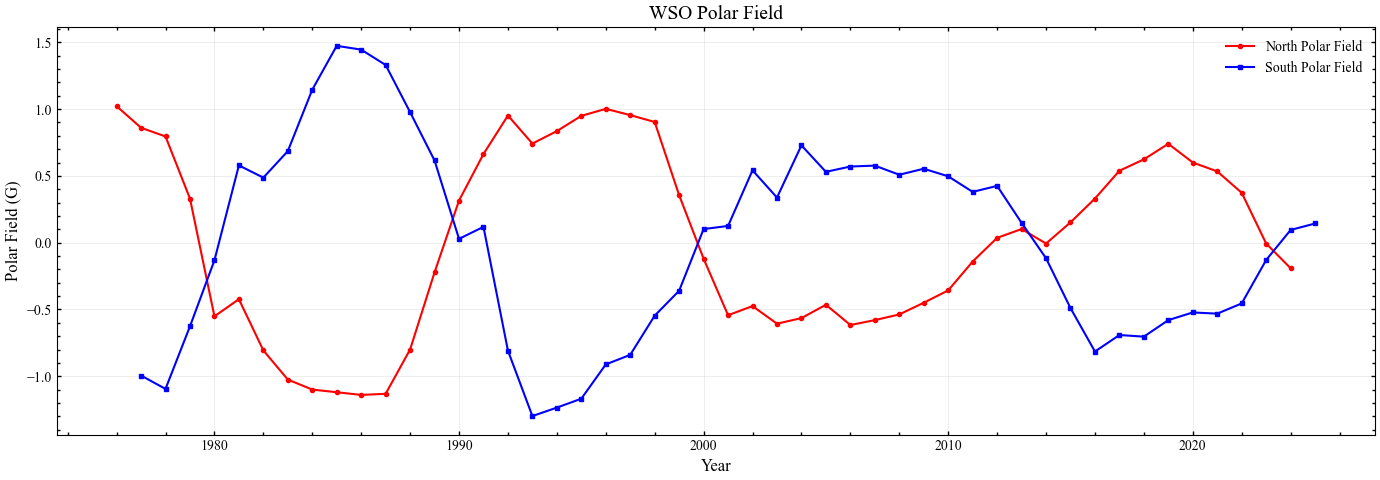

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(
    WSO_df["year"],
    WSO_df["Nf"]/100,
    color="red",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="North Polar Field"
)

plt.plot(
    WSO_df["year"],
    WSO_df["Sf"]/100,
    color="blue",
    marker="s",
    markersize=3,
    linewidth=1.5,
    label="South Polar Field"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Polar Field (G)", fontsize=12)
plt.title("WSO Polar Field", fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [116]:
# col1: Years 
# col2: Polar Field North derived from PNI (calibrated with WSO)
# col3: Error in Polar Field North derived from PNI (calibrated with WSO)
# col4: Polar Field South derived from PNI (calibrated with WSO)
# col5: Error in Polar Field South derived from PNI (calibrated with WSO)
# col6: Polar Field North derived from PNI (calibrated with AFT)
# col7: Error in Polar Field North derived from PNI (calibrated with AFT)
# col8: Polar Field South derived from PNI (calibrated with AFT)
# col9: Error in Polar Field South derived from PNI (calibrated with AFT)

polar_path='/home/iron-man/Documents/long_term_reconstruction/Pix2Pix_Codes/KoSO_CaIIK_polarfield_yearly.txt'
polar_df = pd.read_csv(polar_path, sep='\s+',names=['Date', 'North PNI','col3','South PNI','col5','col6','col7','col8','col9'])
# Keep only required columns
polar_df = polar_df[['Date',
                     'North PNI',
                     'South PNI']]
polar_df = polar_df[
    (polar_df['Date'] >= 1914) &
    (polar_df['Date'] < 2005)
].reset_index(drop=True)
polar_df.head()

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_14400/3592830374.py:12: SyntaxWarning: invalid escape sequence '\s'
  polar_df = pd.read_csv(polar_path, sep='\s+',names=['Date', 'North PNI','col3','South PNI','col5','col6','col7','col8','col9'])


,Date,North PNI,South PNI
0,1914,1.71,-1.49
1,1915,1.04,-1.45
2,1916,1.23,-0.98
3,1917,-0.74,0.70
4,1918,-1.07,0.71


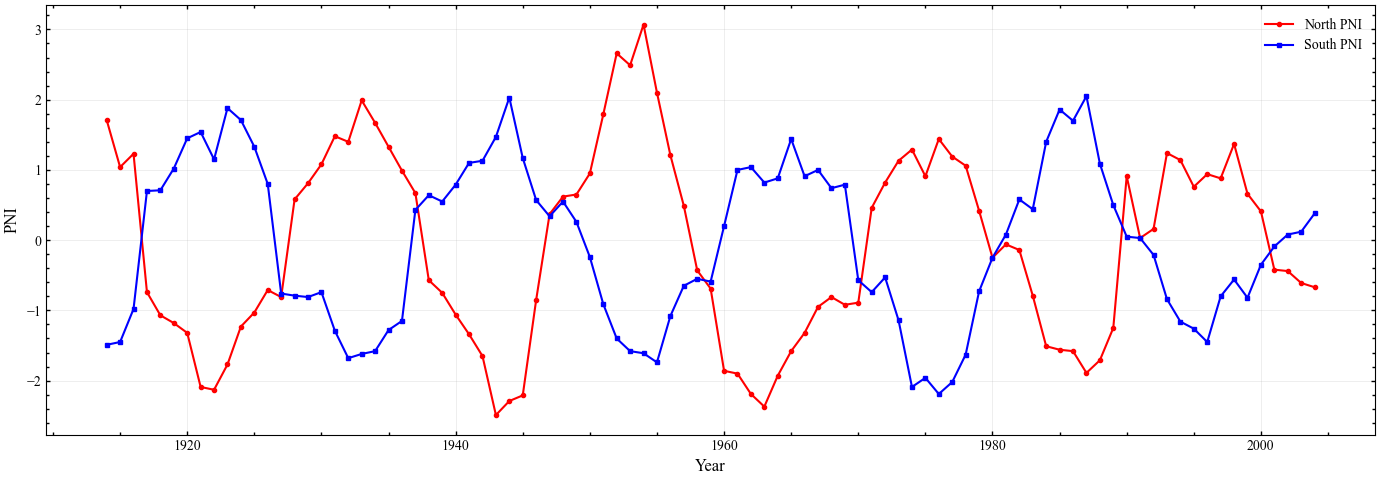

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(
    polar_df["Date"],
    polar_df["North PNI"],
    color="red",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="North PNI"
)

plt.plot(
    polar_df["Date"],
    polar_df["South PNI"],
    color="blue",
    marker="s",
    markersize=3,
    linewidth=1.5,
    label="South PNI"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("PNI", fontsize=12)
# plt.title("WSO Polar Field", fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

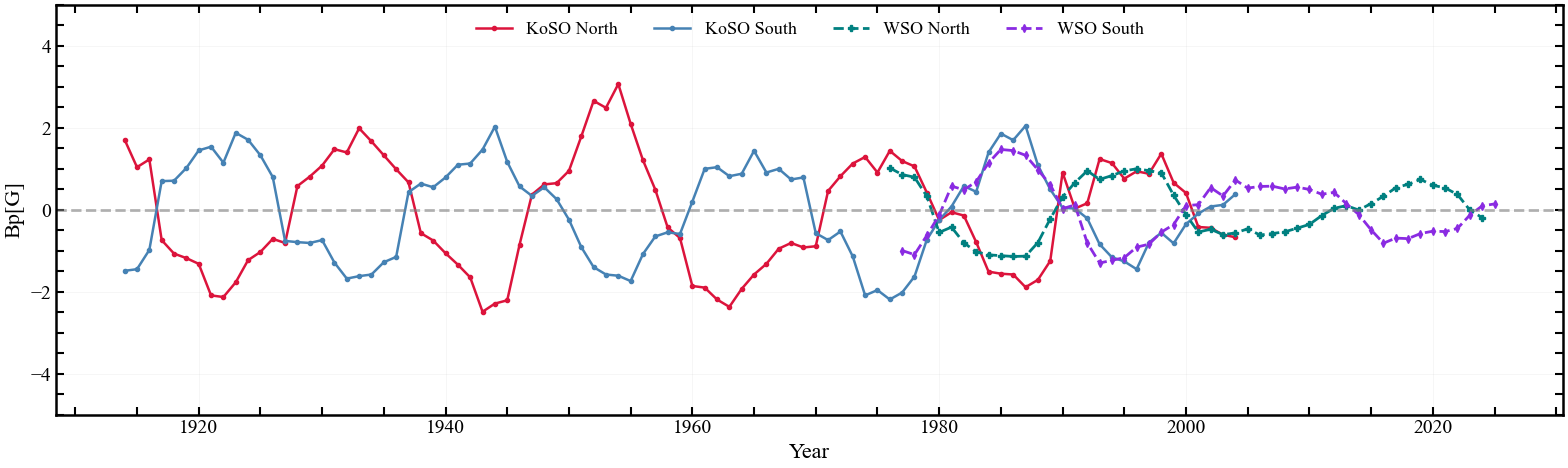

In [118]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 14,
    "axes.linewidth": 1.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

fig, ax = plt.subplots(figsize=(16,5))

# --------------------------
# PNI (KoSO)
# --------------------------
ax.plot(
    polar_df["Date"],
    polar_df["North PNI"],
    color="crimson",
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="KoSO North"
)

ax.plot(
    polar_df["Date"],
    polar_df["South PNI"],
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="KoSO South"
)

# --------------------------
# WSO Polar Field
# --------------------------
ax.plot(
    WSO_df["year"],
    WSO_df["Nf"]/100,
    color="teal",
    marker="P",
    linestyle="--",
    markersize=4,
    linewidth=2,
    label="WSO North"
)

ax.plot(
    WSO_df["year"],
    WSO_df["Sf"]/100,
    color="#8A2BE2",      # purple
    marker="d",
    markersize=4,
    linestyle="--",
    linewidth=2,
    label="WSO South"
)

# Zero line
ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=2,
    alpha=0.6
)

# Labels
ax.set_xlabel("Year", fontsize=16)
ax.set_ylabel("Bp[G]", fontsize=16)
# Y-axis limits
ax.set_ylim(-5, 5)
# Tick style like the paper
ax.tick_params(
    direction="in",
    which="both",
    top=True,
    right=True,
    length=6,
    width=1.5
)

ax.minorticks_on()

# Legend
ax.legend(
    ncol=4,
    loc="upper center",
    frameon=False,
    fontsize=13
)

ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

In [119]:
def norm3(real_image):
    real_image = np.where(np.isnan(real_image), 0.0, real_image)
    real_image = real_image / 750.0
    real_image = np.clip(real_image, -1.0, 1.0)
    return real_image.astype(np.float32)
def denorm(real_image):
    real_image = real_image * 750.0
    return real_image.astype(np.float32)


def sin_lat(img):
    H,W = img.shape
    # Original sin(latitude) grid
    sin_lat = np.linspace(-1, 1, H)
    
    # Target latitude grid
    lat_new = np.linspace(-90, 90, H)
    sin_lat_new = np.sin(np.deg2rad(lat_new))

    # Output image
    magnetogram = np.full_like(img, np.nan)
    for x in range(W):
        f = interp1d(
            sin_lat,
            img[:, x],
            kind='linear',      # or 'cubic'
            bounds_error=False,
            fill_value='extrapolate'
            # fill_value = np.nan
        )
        magnetogram[:, x] = f(sin_lat_new)
    return magnetogram


  0%|                                                 | 0/34566 [00:00<?, ?it/s]/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/home/iron-man/jupyter-env/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/tmp/ipykernel_14400/27568375.py:73: RuntimeWarning: invalid value

Pred_df saved successfully.


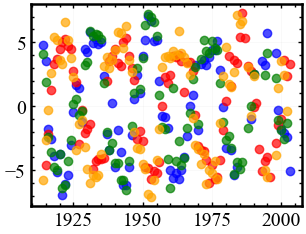

In [120]:
from sunpy.coordinates import sun
# data_dir = "/home/iron-man/Documents/long_term_reconstruction/callibrated/train/target"
# data_dir = "/home/iron-man/Downloads/train_output/predicted_full_disk/Pix_Pix_Model_HD"
data_dir = "/home/iron-man/Downloads/train_output_1/predicted_full_disk_total/Pix_Pix_Model_HD"
lat_threshold = 55.0

nx = ny = 256
rsun = 256 * 0.898 / 2

# ----------------------------------------------

north_dict = defaultdict(list)
south_dict = defaultdict(list)
test_north = defaultdict(list)  #for test dataset time period
test_south = defaultdict(list)  #for test dataset time period
bad_files = []

files = sorted(os.listdir(data_dir))

# ---------- Disk geometry ----------

y, x = np.indices((ny, nx))
cx = cy = nx / 2

x = x - cx
y = y - cy

r = np.sqrt(x**2 + y**2)
disk_mask = r <= rsun

# projection effect
# mu = np.sqrt(1 - (r / rsun)**2)
# mu[~disk_mask] = np.nan


# Optional: heliocentric Z
z = np.sqrt(np.maximum(rsun**2 - x**2 - y**2, 0))


 
# ---------- Loop ----------
for fname in tqdm(files):

    path = os.path.join(data_dir, fname)

    # extract date
    base = os.path.basename(fname)
    date_str = base.split(".")[0]

    try:
        t = Time.strptime(date_str, "%Y%m%d_%H%M")
    except:
        continue

    year = t.datetime.year
    month = t.datetime.month

    with fits.open(path) as hdul:
        Br = hdul[0].data.astype(np.float64)
        Br = denorm(Br)

    if np.all(~np.isfinite(Br)):
        bad_files.append(fname)
        continue
    # ---------- Deproject Blos -> Br ----------
    # Br = np.full((ny, nx), np.nan)
    # Br[disk_mask] = Blos[disk_mask] / mu[disk_mask]


    B0 = sun.B0(t).to_value("deg")
    B0_rad = np.deg2rad(B0)
    # define latitude
    latitude = np.arcsin((y * np.cos(B0_rad) + z * np.sin(B0_rad)) / rsun)
    latitude[~disk_mask] = np.nan
    latitude_deg = np.rad2deg(latitude)
    # latitude in radiun
    lat_rad = np.radians(latitude_deg)
    
    # ---------- Polar masks ----------
    north_mask = (latitude_deg >= lat_threshold) & disk_mask
    south_mask = (latitude_deg <= -lat_threshold) & disk_mask

    # ---------- Area-weighted mean ----------


    w_n = np.cos(lat_rad[north_mask])
    w_s = np.cos(lat_rad[south_mask])

    Bn = np.nansum(Br[north_mask] * w_n) / np.nansum(w_n)
    Bs = np.nansum(Br[south_mask] * w_s) / np.nansum(w_s)

    # ---------- Store by hemisphere months ----------

    if month in [8, 9]:     # Aug–Sep → North
        north_dict[year].append(Bn)
        
    if month in [10, 11]:     # oct–nov → test
        test_north[year].append(Bn)
        test_south[year].append(Bs)
    
    if month in [2, 3]:     # Feb–Mar → South
        south_dict[year].append(Bs)

# # ---------- Compute yearly averages ----------

# years = sorted(set(north_dict.keys()) | set(south_dict.keys()))

# north_pf = []
# south_pf = []
# test_pf = []
# time_list = []

# for year in years:

#     if len(north_dict[year]) > 0:
#         north_pf.append(np.mean(north_dict[year]))
#     else:
#         north_pf.append(np.nan)

#     if len(south_dict[year]) > 0:
#         south_pf.append(np.mean(south_dict[year]))
#     else:
#         south_pf.append(np.nan)

#     if len(test_dict[year]) > 0:
#         test_pf.append(np.mean(test_dict[year]))
#     else:
#         test_pf.append(np.nan)    
    
#     time_list.append(year)

# north_pf = np.array(north_pf)
# south_pf = np.array(south_pf)
# test_pf = np.array(test_pf)
# time_list = np.array(time_list)

# Pred_df = pd.DataFrame({
#     'Date': time_list,
#     'pred_S_pf': south_pf,
#     'pred_N_pf': north_pf,
#     'test_pf' : test_pf
# })

# Pred_df.head()
# ---------- Compute yearly averages ----------

# years = sorted(set(north_dict.keys()) | set(south_dict.keys()))
years = sorted(
    set(north_dict.keys())
    | set(south_dict.keys())
    | set(test_north.keys())
    | set(test_south.keys())
)

north_pf = []
south_pf = []

n_test_pf = []
s_test_pf = []

north_se = []
south_se = []

n_test_se = []
s_test_se = []

time_list = []

for year in years:

    n_vals = north_dict[year]
    s_vals = south_dict[year]
    n_t_vals = test_north[year]
    s_t_vals = test_south[year]

    if len(n_vals) > 0:
        north_pf.append(np.mean(n_vals))
        north_se.append(np.std(n_vals, ddof=1) / np.sqrt(len(n_vals)) if len(n_vals) > 1 else np.nan)
    else:
        north_pf.append(np.nan)
        north_se.append(np.nan)

    if len(s_vals) > 0:
        south_pf.append(np.mean(s_vals))
        south_se.append(np.std(s_vals, ddof=1) / np.sqrt(len(s_vals)) if len(s_vals) > 1 else np.nan)
    else:
        south_pf.append(np.nan)
        south_se.append(np.nan)

    if len(n_t_vals) > 0:
        n_test_pf.append(np.mean(n_t_vals))
        n_test_se.append(np.std(n_t_vals, ddof=1) / np.sqrt(len(n_t_vals)) if len(n_t_vals) > 1 else np.nan)
       
    else:
        n_test_pf.append(np.nan)
        n_test_se.append(np.nan)
        
    if len(s_t_vals) > 0:
        s_test_pf.append(np.mean(s_t_vals))
        s_test_se.append(np.std(s_t_vals, ddof=1) / np.sqrt(len(s_t_vals)) if len(s_t_vals) > 1 else np.nan)
    else:
        s_test_pf.append(np.nan)
        s_test_se.append(np.nan)

    time_list.append(year)

north_pf = np.array(north_pf)
south_pf = np.array(south_pf)
n_test_pf  = np.array(n_test_pf)
s_test_pf  = np.array(s_test_pf)

north_se = np.array(north_se)
south_se = np.array(south_se)
n_test_se  = np.array(n_test_se)
s_test_se  = np.array(s_test_se)
time_list = np.array(time_list)

Pred_df = pd.DataFrame({
    'Date': time_list,
    'pred_S_pf': south_pf,
    'pred_S_se': south_se,
    'pred_N_pf': north_pf,
    'pred_N_se': north_se,
    'n_test_pf': n_test_pf,
    'n_test_se': n_test_se,
    's_test_pf': s_test_pf,
    's_test_se': s_test_se,
})
# Save DataFrame
Pred_df.to_csv(
    '/home/iron-man/Documents/long_term_reconstruction/Pred_polar_field.csv',
    index=False
)

print("Pred_df saved successfully.")
Pred_df.head()
plt.scatter(time_list, north_pf, color='blue', label='North', alpha=0.7)
plt.scatter(time_list, south_pf, color='red', label='South', alpha=0.7)
plt.scatter(time_list, n_test_pf, color='green', label='North Test', alpha=0.7)
plt.scatter(time_list, s_test_pf, color='orange', label='South Test', alpha=0.7)

In [121]:
Pred_df.head()

,Date,pred_S_pf,pred_S_se,pred_N_pf,pred_N_se,n_test_pf,n_test_se,s_test_pf,s_test_se
0,1914,NaN,NaN,4.783144,0.088888,4.081654,0.290969,-5.756548,0.124723
1,1915,-4.611590,0.067086,3.548148,0.131014,1.929005,0.111557,-2.629831,0.130335
2,1916,-2.201741,0.094286,-1.769644,0.113821,-2.390313,0.149169,-0.323179,0.202758
3,1917,1.275216,0.096052,-2.554912,0.118131,-3.587392,0.110428,2.623016,0.090089
4,1918,3.276512,0.060222,-3.881713,0.080281,-4.718616,0.062756,5.402163,0.093838


In [194]:
# fig, ax = plt.subplots(figsize=(11, 5))

# # North
# ax.plot(Pred_df['Date'], Pred_df['pred_N_pf'], color='red', label='North (pred)')
# ax.fill_between(
#     Pred_df['Date'],
#     Pred_df['pred_N_pf'] - Pred_df['pred_N_se'],
#     Pred_df['pred_N_pf'] + Pred_df['pred_N_se'],
#     color='red', alpha=0.25
# )

# # South
# ax.plot(Pred_df['Date'], Pred_df['pred_S_pf'], color='blue', label='South (pred)')
# ax.fill_between(
#     Pred_df['Date'],
#     Pred_df['pred_S_pf'] - Pred_df['pred_S_se'],
#     Pred_df['pred_S_pf'] + Pred_df['pred_S_se'],
#     color='blue', alpha=0.25
# )

# # Test / reference
# ax.plot(Pred_df['Date'], Pred_df['n_test_pf'], color='orange', linestyle='--', label='Target(north)')
# ax.fill_between(
#     Pred_df['Date'],
#     Pred_df['n_test_pf'] - Pred_df['n_test_se'],
#     Pred_df['n_test_pf'] + Pred_df['n_test_se'],
#     color='gray', alpha=0.25
# )
# # Test / reference
# ax.plot(Pred_df['Date'], Pred_df['s_test_pf'], color='yellow', linestyle='--', label='Target(south)')
# ax.fill_between(
#     Pred_df['Date'],
#     Pred_df['s_test_pf'] - Pred_df['s_test_se'],
#     Pred_df['s_test_pf'] + Pred_df['s_test_se'],
#     color='gray', alpha=0.25
# )

# ax.set_xlabel("Year")
# ax.set_ylabel("Polar field [G]")
# ax.legend()
# plt.tight_layout()
# plt.show()

# fig, ax = plt.subplots(figsize=(11, 5))

# ax.errorbar(
#     Pred_df['Date'], Pred_df['pred_N_pf'], yerr=Pred_df['pred_N_se'],
#     fmt='-o', color='red', ecolor='red', elinewidth=1, capsize=3,
#     markersize=3, label='North (pred)'
# )

# ax.errorbar(
#     Pred_df['Date'], Pred_df['pred_S_pf'], yerr=Pred_df['pred_S_se'],
#     fmt='-o', color='blue', ecolor='blue', elinewidth=1, capsize=3,
#     markersize=3, label='South (pred)'
# )

# ax.errorbar(
#     Pred_df['Date'], Pred_df['n_test_pf'], yerr=Pred_df['n_test_se'],
#     fmt='--s', color='black', ecolor='gray', elinewidth=1, capsize=3,
#     markersize=3, label='Target'
# )
# ax.errorbar(
#     Pred_df['Date'], Pred_df['s_test_pf'], yerr=Pred_df['s_test_se'],
#     fmt='--s', color='black', ecolor='gray', elinewidth=1, capsize=3,
#     markersize=3, label='Target'
# )
# ax.set_xlabel("Year")
# ax.set_ylabel("Polar field [G]")
# ax.legend()
# plt.tight_layout()
# plt.show()

In [195]:
# Pred_df.head()
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates


# import matplotlib.pyplot as plt

# plt.figure(figsize=(14,5))

# plt.plot(
#     Pred_df["Date"],
#     Pred_df["pred_N_pf"],
#     color="red",
#     marker="o",
#     markersize=3,
#     linewidth=1.5,
#     label="North polar"
# )

# plt.plot(
#     Pred_df["Date"],
#     Pred_df["pred_S_pf"],
#     color="blue",
#     marker="s",
#     markersize=3,
#     linewidth=1.5,
#     label="South polar"
# )

# plt.xlabel("Year", fontsize=12)
# plt.ylabel("polar", fontsize=12)
# # plt.title("WSO Polar Field", fontsize=14)
# plt.grid(True, alpha=0.3)
# plt.legend()

# plt.tight_layout()
# plt.show()

# import numpy as np

# Pred_df["North_sign_change"] = (
#     Pred_df["pred_N_pf"] * Pred_df["pred_N_pf"].shift(1) < 0
# )

# Pred_df["South_sign_change"] = (
#     Pred_df["pred_S_pf"] * Pred_df["pred_S_pf"].shift(1) < 0
# )

# print(Pred_df[Pred_df["North_sign_change"]])
# print(Pred_df[Pred_df["South_sign_change"]])

In [196]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates

# df = Pred_df.copy()

# # ============================================================
# # Convert year to datetime
# # ============================================================

# df["Date"] = pd.to_datetime(
#     df["Date"].astype(str),
#     format="%Y"
# )

# df = df.sort_values("Date").reset_index(drop=True)


# # # ============================================================
# # # Smooth polar fields
# # # ============================================================

# window = 3   # 5-year running mean

# df["N_smooth"] = (
#     df["pred_N_pf"]
#     .rolling(
#         window=window,
#         center=True,
#         min_periods=3
#     )
#     .mean()
# )

# df["S_smooth"] = (
#     df["pred_S_pf"]
#     .rolling(
#         window=window,
#         center=True,
#         min_periods=3
#     )
#     .mean()
# )


# # ============================================================
# # Find polarity reversals
# # ============================================================

# def find_zero_crossings(df, field):

#     reversal_dates = []

#     for i in range(1, len(df)):

#         y1 = df[field].iloc[i-1]
#         y2 = df[field].iloc[i]

#         if pd.isna(y1) or pd.isna(y2):
#             continue

#         # Sign change
#         if y1 * y2 < 0:

#             t1 = df["Date"].iloc[i-1]
#             t2 = df["Date"].iloc[i]

#             # Linear interpolation
#             fraction = -y1 / (y2 - y1)

#             reversal_date = t1 + (t2 - t1) * fraction

#             reversal_dates.append(reversal_date)

#     return reversal_dates


# north_reversal = find_zero_crossings(
#     df,
#     "N_smooth"
# )

# south_reversal = find_zero_crossings(
#     df,
#     "S_smooth"
# )


# # ============================================================
# # Print reversal dates
# # ============================================================

# print("\nNorth polarity reversals:")

# for date in north_reversal:
#     print(date.strftime("%Y-%m-%d"))


# print("\nSouth polarity reversals:")

# for date in south_reversal:
#     print(date.strftime("%Y-%m-%d"))


# # print("\nNorth polarity reversals:")

# # for date in north_reversal:
# #     print(date)


# # print("\nSouth polarity reversals:")

# # for date in south_reversal:
# #     print(date)

# # ============================================================
# # Plot
# # ============================================================

# fig, ax = plt.subplots(figsize=(14, 5))


# # ------------------------------------------------------------
# # Raw polar fields
# # ------------------------------------------------------------

# ax.plot(
#     df["Date"],
#     df["pred_N_pf"],
#     color="red",
#     alpha=0.25,
#     linewidth=1,
#     label="North raw"
# )

# ax.plot(
#     df["Date"],
#     df["pred_S_pf"],
#     color="blue",
#     alpha=0.25,
#     linewidth=1,
#     label="South raw"
# )


# # ------------------------------------------------------------
# # Smoothed polar fields
# # ------------------------------------------------------------

# ax.plot(
#     df["Date"],
#     df["N_smooth"],
#     color="red",
#     linewidth=2,
#     label="North smoothed"
# )

# ax.plot(
#     df["Date"],
#     df["S_smooth"],
#     color="blue",
#     linewidth=2,
#     label="South smoothed"
# )


# # ------------------------------------------------------------
# # Zero polarity line
# # ------------------------------------------------------------

# ax.axhline(
#     0,
#     color="black",
#     linestyle="--",
#     linewidth=1
# )


# # ------------------------------------------------------------
# # North reversal dates
# # ------------------------------------------------------------

# for date in north_reversal:

#     ax.axvline(
#         date,
#         color="red",
#         linestyle=":",
#         linewidth=1.5,
#         alpha=0.8
#     )


# # ------------------------------------------------------------
# # South reversal dates
# # ------------------------------------------------------------

# for date in south_reversal:

#     ax.axvline(
#         date,
#         color="blue",
#         linestyle=":",
#         linewidth=1.5,
#         alpha=0.8
#     )


# # ============================================================
# # X-axis: every 5 years
# # ============================================================

# ax.xaxis.set_major_locator(
#     mdates.YearLocator(5)
# )

# ax.xaxis.set_major_formatter(
#     mdates.DateFormatter("%Y")
# )

# ax.set_xlim(
#     df["Date"].min(),
#     df["Date"].max()
# )


# # ============================================================
# # Labels
# # ============================================================

# ax.set_xlabel(
#     "Year",
#     fontsize=12
# )

# ax.set_ylabel(
#     "Polar Field",
#     fontsize=12
# )

# ax.grid(
#     True,
#     alpha=0.3
# )

# ax.legend()

# plt.tight_layout()
# plt.show()

  0%|                                                  | 0/4935 [00:00<?, ?it/s]/tmp/ipykernel_14400/2377985133.py:71: RuntimeWarning: invalid value encountered in arcsin
  latitude = np.arcsin((y * np.cos(B0_rad) + z * np.sin(B0_rad)) / rsun)
100%|██████████████████████████████████████| 4935/4935 [00:23<00:00, 207.06it/s]


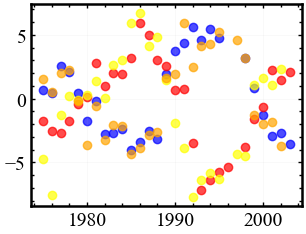

In [123]:
from sunpy.coordinates import sun
data_dir = "/home/iron-man/Documents/long_term_reconstruction/callibrated/train/total_target"
lat_threshold = 55.0

nx = ny = 256
rsun = 256 * 0.898 / 2

# ----------------------------------------------

north_dict = defaultdict(list)
south_dict = defaultdict(list)
n_test_dict = defaultdict(list)
s_test_dict = defaultdict(list)
bad_files = []

files = sorted(os.listdir(data_dir))

# ---------- Disk geometry ----------

y, x = np.indices((ny, nx))
cx = cy = nx / 2

x = x - cx
y = y - cy

r = np.sqrt(x**2 + y**2)
disk_mask = r <= rsun

# projection effect
# mu = np.sqrt(1 - (r / rsun)**2)
# mu[~disk_mask] = np.nan


# Optional: heliocentric Z
z = np.sqrt(np.maximum(rsun**2 - x**2 - y**2, 0))


 
# ---------- Loop ----------
for fname in tqdm(files):

    path = os.path.join(data_dir, fname)

    # extract date
    base = os.path.basename(fname)
    date_str = base.split(".")[0]

    try:
        t = Time.strptime(date_str, "%Y%m%d_%H%M")
    except:
        continue

    year = t.datetime.year
    month = t.datetime.month

    with fits.open(path) as hdul:
        Br = hdul[0].data.astype(np.float64)
        # Br = denorm(Br)

    if np.all(~np.isfinite(Br)):
        bad_files.append(fname)
        continue
    # ---------- Deproject Blos -> Br ----------
    # Br = np.full((ny, nx), np.nan)
    # Br[disk_mask] = Blos[disk_mask] / mu[disk_mask]


    B0 = sun.B0(t).to_value("deg")
    B0_rad = np.deg2rad(B0)
    # define latitude
    latitude = np.arcsin((y * np.cos(B0_rad) + z * np.sin(B0_rad)) / rsun)
    latitude[~disk_mask] = np.nan
    latitude_deg = np.rad2deg(latitude)
    # latitude in radiun
    lat_rad = np.radians(latitude_deg)
    
    # ---------- Polar masks ----------
    north_mask = (latitude_deg >= lat_threshold) & disk_mask
    south_mask = (latitude_deg <= -lat_threshold) & disk_mask

    # ---------- Area-weighted mean ----------


    w_n = np.cos(lat_rad[north_mask])
    w_s = np.cos(lat_rad[south_mask])

    Bn = np.nansum(Br[north_mask] * w_n) / np.nansum(w_n)
    Bs = np.nansum(Br[south_mask] * w_s) / np.nansum(w_s)

    # ---------- Store by hemisphere months ----------

    if month in [8, 9]:     # Aug–Sep → North
        north_dict[year].append(Bn)

    if month in [2, 3]:     # Feb–Mar → South
        south_dict[year].append(Bs)

    if month in [10, 11]:     # oct–Nov → test
        n_test_dict[year].append(Bn)
        s_test_dict[year].append(Bs)
# ---------- Compute yearly averages ----------

# years = sorted(set(north_dict.keys()) | set(south_dict.keys()))
years = sorted(
    set(north_dict.keys())
    | set(south_dict.keys())
    | set(n_test_dict.keys())
    | set(s_test_dict.keys())
)

north_pf = []
south_pf = []
KP_n_test_pf = []
KP_n_test_se = []

KP_s_test_pf = []
KP_s_test_se = []
time_list = []

for year in years:

    if len(north_dict[year]) > 0:
        north_pf.append(np.mean(north_dict[year]))
    else:
        north_pf.append(np.nan)

    if len(south_dict[year]) > 0:
        south_pf.append(np.mean(south_dict[year]))
    else:
        south_pf.append(np.nan)

    if len(n_test_dict[year]) > 0:
        KP_n_test_pf.append(np.mean(n_test_dict[year]))
        KP_n_test_se.append(np.std(n_test_dict[year], ddof=1) / np.sqrt(len(n_test_dict[year])) if len(n_test_dict[year]) > 1 else np.nan)
    else:
        KP_n_test_pf.append(np.nan)
        KP_n_test_se.append(np.nan)

    if len(s_test_dict[year]) > 0:
        KP_s_test_pf.append(np.mean(s_test_dict[year]))
        KP_s_test_se.append(np.std(s_test_dict[year], ddof=1) / np.sqrt(len(s_test_dict[year])) if len(s_test_dict[year]) > 1 else np.nan)
    else:
        KP_s_test_pf.append(np.nan)
        KP_s_test_se.append(np.nan)
    time_list.append(year)



        
north_pf = np.array(north_pf)
south_pf = np.array(south_pf)
KP_n_test_pf = np.array(KP_n_test_pf)
KP_n_test_se = np.array(KP_n_test_se)
KP_s_test_pf = np.array(KP_s_test_pf)
KP_s_test_se = np.array(KP_s_test_se)
time_list = np.array(time_list)

Kitt_peak_df = pd.DataFrame({
    'Date': time_list,
    'KP_S_pf': south_pf,
    'KP_N_pf': north_pf,
    'KP_n_test_pf': KP_n_test_pf,
    'KP_n_test_se': KP_n_test_se,
    'KP_s_test_pf': KP_s_test_pf,
    'KP_s_test_se': KP_s_test_se,
})
# Save DataFrame
Kitt_peak_df.to_csv(
    '/home/iron-man/Documents/long_term_reconstruction/Kitt_peak_df.csv',
    index=False
)
Kitt_peak_df.head()
plt.scatter(time_list, north_pf, color='blue', label='North', alpha=0.7)
# plt.scatter(time_list, KP_test_pf, color='green', label='North', alpha=0.7)
plt.scatter(time_list, south_pf, color='red', label='South', alpha=0.7)
plt.scatter(time_list, KP_s_test_pf, color='yellow', label='south', alpha=0.7)
plt.scatter(time_list, KP_n_test_pf, color='orange', label='North', alpha=0.7)

In [124]:
Kitt_peak_df.head()

,Date,KP_S_pf,KP_N_pf,KP_n_test_pf,KP_n_test_se,KP_s_test_pf,KP_s_test_se
0,1975,-1.742854,0.661294,1.557067,0.154254,-4.749082,0.239134
1,1976,-2.557973,0.436255,0.544544,0.342247,-7.532072,0.283168
2,1977,-2.685643,2.582291,2.016822,0.267983,-1.251812,0.536856
3,1978,-1.709871,2.094326,2.249438,0.081992,0.207817,0.285943
4,1979,-0.448609,0.448967,-0.213522,0.220392,-0.121730,0.562860


In [125]:
df1 = polar_df[['Date','South PNI']]
df2 = Pred_df[['Date','pred_S_pf']]


df1 = df1[(df1['Date'] >= 1915) & (df1['Date'] <= 2003)]
df2 = df2[(df2['Date'] >= 1915) & (df2['Date'] <= 2003)]



merged = pd.merge(df1, df2, on='Date', how='inner')
merged = merged.dropna()

x = merged['South PNI'].values
y = merged['pred_S_pf'].values

slope_pred, intercept_pred = np.polyfit(x, y, 1)

print("Slope_pred:", slope_pred)
print("Intercept_pred:", intercept_pred)


df1 = polar_df[['Date','South PNI']]
df2 = Kitt_peak_df[['Date','KP_S_pf']]


df1 = df1[(df1['Date'] >= 1915) & (df1['Date'] <= 2003)]
df2 = df2[(df2['Date'] >= 1915) & (df2['Date'] <= 2003)]



merged = pd.merge(df1, df2, on='Date', how='inner')
merged = merged.dropna()

x = merged['South PNI'].values
y = merged['KP_S_pf'].values

slope_KP, intercept_KP = np.polyfit(x, y, 1)

print("Slope_KP:", slope_KP)
print("Intercept_KP:", intercept_KP)

Slope_pred: 2.9798613958190248
Intercept_pred: 0.226252962474879
Slope_KP: 2.3190855212764934
Intercept_KP: 0.16318965368929683


In [126]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
dfN1_P = polar_df[['Date','North PNI']]
dfN2_P = Pred_df[['Date','pred_N_pf']]


dfN1_P = dfN1_P[(dfN1_P['Date'] >= 1915) & (dfN1_P['Date'] <= 2003)]
dfN2_P = dfN2_P[(dfN2_P['Date'] >= 1915) & (dfN2_P['Date'] <= 2003)]
merged_N_P = pd.merge(dfN1_P, dfN2_P, on='Date', how='inner')
merged_N_P = merged_N_P.dropna()


dfS1_P = polar_df[['Date','South PNI']]
dfS2_P = Pred_df[['Date','pred_S_pf']]


dfS1_P = dfS1_P[(dfS1_P['Date'] >= 1915) & (dfS1_P['Date'] <= 2003)]
dfS2_P = dfS2_P[(dfS2_P['Date'] >= 1915) & (dfS2_P['Date'] <= 2003)]
merged_S_P = pd.merge(dfS1_P, dfS2_P, on='Date', how='inner')
merged_S_P = merged_S_P.dropna()
x = np.concatenate([
    merged_N_P['North PNI'].values,
    merged_S_P['South PNI'].values
])

y = np.concatenate([
    merged_N_P['pred_N_pf'].values,
    merged_S_P['pred_S_pf'].values
])
# Correlation coefficients
pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

# slope_pred, intercept_pred = np.polyfit(x, y, 1)
coeffs, cov = np.polyfit(x, y, 1, cov=True)

slope_pred = coeffs[0]
intercept_pred = coeffs[1]

slope_err = np.sqrt(cov[0,0])
y_pred = (y-intercept_pred)/slope_pred
# Calculate metrics
n_pred = len(x)
mse_pred = np.mean((y_pred - x) ** 2) # Mean Squared Error
rmse_pred = np.sqrt(mse_pred)              # Root Mean Squared Error
mae_pred = np.mean(np.abs(y_pred - x)) # Mean Absolute Error
# r2_pred = r2_score(x, y_pred)         # R-squared
r2_calibration = r2_score(x, y_pred)  
# Print results
print("=" * 50)
print("PREDICTED vs PNI")
print("=" * 50)
print("Slope_pred:", slope_pred)
print("slope error:" , slope_err)
print("Intercept_pred:", intercept_pred)
print(f"RMSE:      {rmse_pred:.4f}")
print(f"MAE:       {mae_pred:.4f}")
print(f"R²_cal:        {r2_calibration:.4f}")
print(f"Pearson r:     {pearson_r:.4f}  (p={pearson_p:.2e})")
print(f"Spearman rho:  {spearman_r:.4f}  (p={spearman_p:.2e})")
print(f"n (points): {n_pred}")







dfN1_KP = polar_df[['Date','North PNI']]
dfN2_KP = Kitt_peak_df[['Date','KP_N_pf']]


dfN1_KP = dfN1_KP[(dfN1_KP['Date'] >= 1915) & (dfN1_KP['Date'] <= 2003)]
dfN2_KP = dfN2_KP[(dfN2_KP['Date'] >= 1915) & (dfN2_KP['Date'] <= 2003)]
merged_N_KP = pd.merge(dfN1_KP, dfN2_KP, on='Date', how='inner')
merged_N_KP = merged_N_KP.dropna()


dfS1_KP = polar_df[['Date','South PNI']]
dfS2_KP = Kitt_peak_df[['Date','KP_S_pf']]


dfS1_KP = dfS1_KP[(dfS1_KP['Date'] >= 1915) & (dfS1_KP['Date'] <= 2003)]
dfS2_KP = dfS2_KP[(dfS2_KP['Date'] >= 1915) & (dfS2_KP['Date'] <= 2003)]
merged_S_KP = pd.merge(dfS1_KP, dfS2_KP, on='Date', how='inner')
merged_S_KP = merged_S_KP.dropna()
x = np.concatenate([
    merged_N_KP['North PNI'].values,
    merged_S_KP['South PNI'].values
])

y = np.concatenate([
    merged_N_KP['KP_N_pf'].values,
    merged_S_KP['KP_S_pf'].values
])






# Correlation coefficients
pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

slope_KP, intercept_KP = np.polyfit(x, y, 1)
y_pred = (y-intercept_KP)/slope_KP
# Calculate metrics
n_pred = len(x)
mse_pred = np.mean((y_pred - x) ** 2) # Mean Squared Error
rmse_pred = np.sqrt(mse_pred)              # Root Mean Squared Error
mae_pred = np.mean(np.abs(y_pred - x)) # Mean Absolute Error
# r2_pred = r2_score(x, y_pred)         # R-squared
r2_calibration = r2_score(x, y_pred)  
# Print results
print("=" * 50)
print("Kitt Peak vs PNI")
print("=" * 50)
print("Slope_KP:", slope_KP)
print("Intercept_KP:", intercept_KP)
print(f"RMSE:      {rmse_pred:.4f}")
print(f"MAE:       {mae_pred:.4f}")
print(f"R²_cal:        {r2_calibration:.4f}")
print(f"Pearson r:     {pearson_r:.4f}  (p={pearson_p:.2e})")
print(f"Spearman rho:  {spearman_r:.4f}  (p={spearman_p:.2e})")
print(f"n (points): {n_pred}")

PREDICTED vs PNI
Slope_pred: 2.738340958503581
slope error: 0.10818107708463065
Intercept_pred: 0.15555054638136342
RMSE:      0.6339
MAE:       0.4762
R²_cal:        0.7409
Pearson r:     0.8912  (p=7.10e-59)
Spearman rho:  0.8945  (p=6.31e-60)
n (points): 168
Kitt Peak vs PNI
Slope_KP: 2.2401263797931064
Intercept_KP: 0.23071164847867145
RMSE:      0.9535
MAE:       0.7583
R²_cal:        0.2401
Pearson r:     0.7538  (p=3.09e-11)
Spearman rho:  0.7909  (p=6.81e-13)
n (points): 55


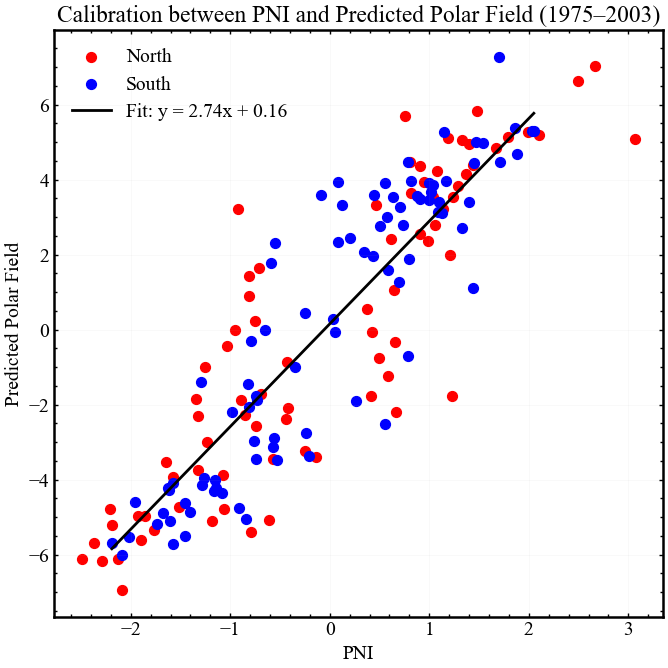

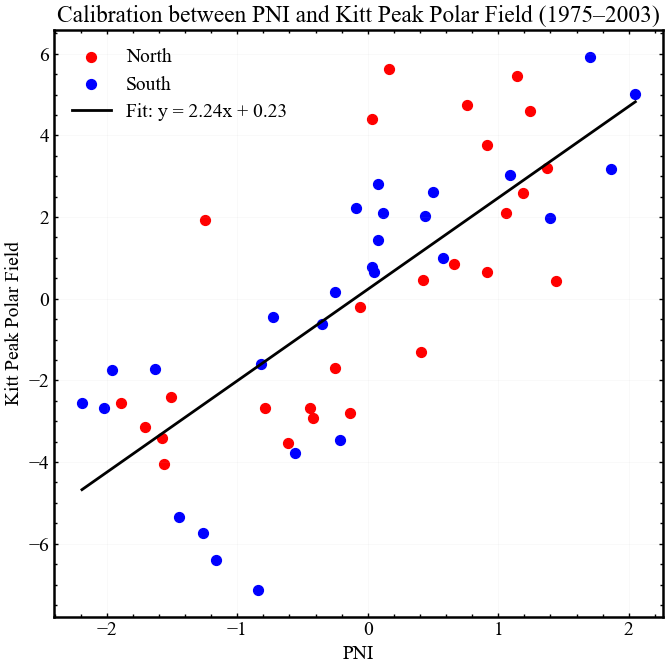

In [127]:
import matplotlib.pyplot as plt
import numpy as np

# Regression line
x_line = np.linspace(min(x), max(x), 200)
y_line = slope_pred * x_line + intercept_pred

plt.figure(figsize=(7,7))

# Scatter plots
plt.scatter(merged_N_P['North PNI'], merged_N_P['pred_N_pf'],
            color='red', label='North', s=50)

plt.scatter(merged_S_P['South PNI'], merged_S_P['pred_S_pf'],
            color='blue', label='South', s=50)

# Regression line
plt.plot(x_line, y_line, color='black', linewidth=2,
         label=f'Fit: y = {slope_pred:.2f}x + {intercept_pred:.2f}')

plt.xlabel("PNI")
plt.ylabel("Predicted Polar Field")
plt.title("Calibration between PNI and Predicted Polar Field (1975–2003)")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import numpy as np

# Regression line
x_line = np.linspace(min(x), max(x), 200)
y_line = slope_KP * x_line + intercept_KP

plt.figure(figsize=(7,7))

# Scatter plots
plt.scatter(merged_N_KP['North PNI'], merged_N_KP['KP_N_pf'],
            color='red', label='North', s=50)

plt.scatter(merged_S_KP['South PNI'], merged_S_KP['KP_S_pf'],
            color='blue', label='South', s=50)

# Regression line
plt.plot(x_line, y_line, color='black', linewidth=2,
         label=f'Fit: y = {slope_KP:.2f}x + {intercept_KP:.2f}')

plt.xlabel("PNI")
plt.ylabel("Kitt Peak Polar Field")
plt.title("Calibration between PNI and Kitt Peak Polar Field (1975–2003)")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

PREDICTED vs target
Slope_pred: 1.0581488501539702
slope error: 0.07869837567416603
Intercept_pred: 0.01173640699354102
RMSE:      1.6043
MAE:       1.2880
R²_cal:        0.7456
Pearson r:     0.8928  (p=1.51e-17)
Spearman rho:  0.8789  (p=2.17e-16)
n (points): 48


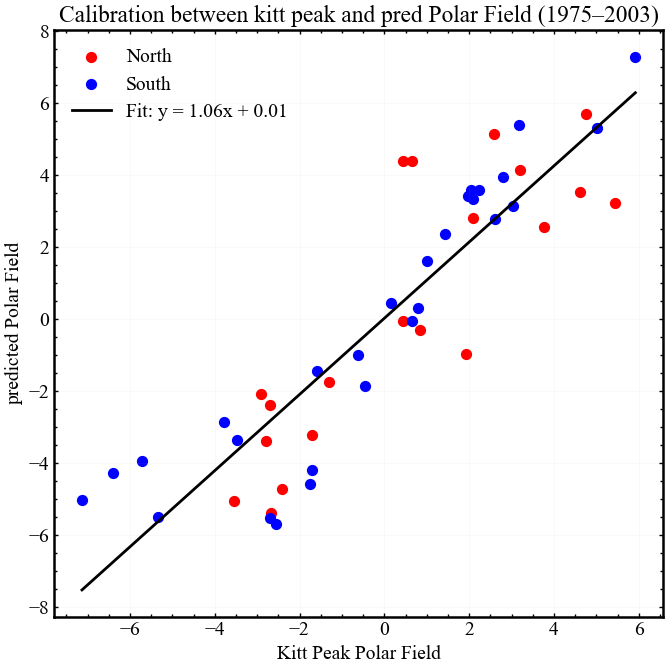

In [128]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
# dfN1_P = polar_df[['Date','North PNI']]
dfN1_KP = Kitt_peak_df[['Date','KP_N_pf']]
dfN2_P = Pred_df[['Date','pred_N_pf']]


dfN1_KP = dfN1_KP[(dfN1_KP['Date'] >= 1915) & (dfN1_KP['Date'] <= 2003)]
dfN2_P = dfN2_P[(dfN2_P['Date'] >= 1915) & (dfN2_P['Date'] <= 2003)]
merged_N_P = pd.merge(dfN1_KP, dfN2_P, on='Date', how='inner')
merged_N_P = merged_N_P.dropna()


# dfS1_P = polar_df[['Date','South PNI']]
dfS1_KP = Kitt_peak_df[['Date','KP_S_pf']]
dfS2_P = Pred_df[['Date','pred_S_pf']]


dfS1_KP = dfS1_KP[(dfS1_KP['Date'] >= 1915) & (dfS1_KP['Date'] <= 2003)]
dfS2_P = dfS2_P[(dfS2_P['Date'] >= 1915) & (dfS2_P['Date'] <= 2003)]
merged_S_P = pd.merge(dfS1_KP, dfS2_P, on='Date', how='inner')
merged_S_P = merged_S_P.dropna()
x = np.concatenate([
    merged_N_P['KP_N_pf'].values,
    merged_S_P['KP_S_pf'].values
])

y = np.concatenate([
    merged_N_P['pred_N_pf'].values,
    merged_S_P['pred_S_pf'].values
])
# Correlation coefficients
pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

# slope_pred, intercept_pred = np.polyfit(x, y, 1)
coeffs, cov = np.polyfit(x, y, 1, cov=True)

slope_KP_pred = coeffs[0]
intercept_KP_pred = coeffs[1]

slope_err = np.sqrt(cov[0,0])
y_pred = (y-intercept_KP_pred)/slope_KP_pred
# Calculate metrics
n_pred = len(x)
mse_pred = np.mean((y_pred - x) ** 2) # Mean Squared Error
rmse_pred = np.sqrt(mse_pred)              # Root Mean Squared Error
mae_pred = np.mean(np.abs(y_pred - x)) # Mean Absolute Error
# r2_pred = r2_score(x, y_pred)         # R-squared
r2_calibration = r2_score(x, y_pred)  
# Print results
print("=" * 50)
print("PREDICTED vs target")
print("=" * 50)
print("Slope_pred:", slope_KP_pred)
print("slope error:" , slope_err)
print("Intercept_pred:", intercept_KP_pred)
print(f"RMSE:      {rmse_pred:.4f}")
print(f"MAE:       {mae_pred:.4f}")
print(f"R²_cal:        {r2_calibration:.4f}")
print(f"Pearson r:     {pearson_r:.4f}  (p={pearson_p:.2e})")
print(f"Spearman rho:  {spearman_r:.4f}  (p={spearman_p:.2e})")
print(f"n (points): {n_pred}")



import matplotlib.pyplot as plt
import numpy as np

# Regression line
x_line = np.linspace(min(x), max(x), 200)
y_line = slope_KP_pred * x_line + intercept_KP_pred

plt.figure(figsize=(7,7))

# Scatter plots
plt.scatter(merged_N_P['KP_N_pf'], merged_N_P['pred_N_pf'],
            color='red', label='North', s=50)

plt.scatter(merged_S_P['KP_S_pf'], merged_S_P['pred_S_pf'],
            color='blue', label='South', s=50)
# Regression line
plt.plot(x_line, y_line, color='black', linewidth=2,
         label=f'Fit: y = {slope_KP_pred:.2f}x + {intercept_KP_pred:.2f}')

plt.xlabel("Kitt Peak Polar Field")
plt.ylabel("predicted Polar Field")
plt.title("Calibration between kitt peak and pred Polar Field (1975–2003)")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


Calibration Parameters
Predicted Polar Field:
  Scaling factor = 2.7383
  Intercept       = 0.1556

KP Polar Field:
  Scaling factor = 2.2401
  Intercept       = 0.2307


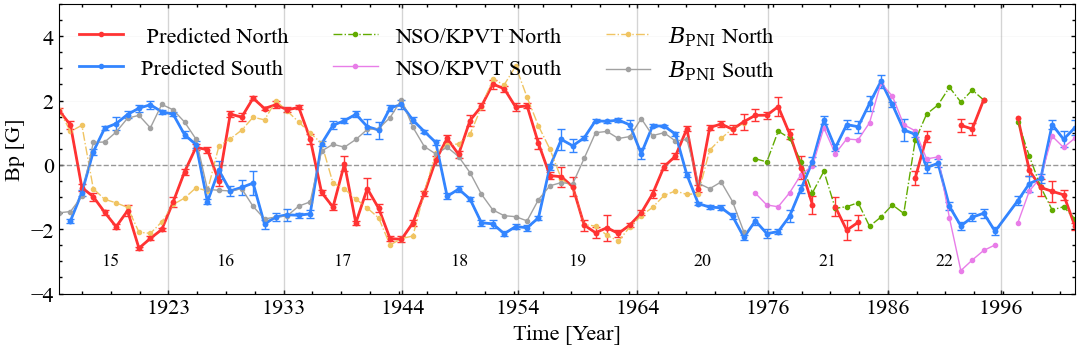

In [193]:
# (cycle_number, start_year, start_month, end_year, end_month)
SOLAR_CYCLES = [
    (15, 1913,  7, 1923,  8),
    (16, 1923,  8, 1933,  9),
    (17, 1933,  9, 1944,  2),
    (18, 1944,  2, 1954,  3),
    (19, 1954,  4, 1964,  9),
    (20, 1964, 10, 1976,  2),
    (21, 1976,  3, 1986,  8),
    (22, 1986,  9, 1996,  7),
    # (23, 1996,  8, 2008, 11),
]



# Check available fonts and set publication-ready style
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
polar_df = polar_df[
    (polar_df['Date'] >= 1914) &
    (polar_df['Date'] < 1975)
].reset_index(drop=True)
polar_df.head()
mpl.style.use('/home/iron-man/Documents/long_term_reconstruction/Pix2Pix_Codes/bkj_style.mplstyle')

scaling_factor_pred = slope_pred
intercept_pred = intercept_pred
scaling_factor_KP = slope_KP
intercept_KP = intercept_KP


print("========================================")
print("Calibration Parameters")
print("========================================")

print(f"Predicted Polar Field:")
print(f"  Scaling factor = {scaling_factor_pred:.4f}")
print(f"  Intercept       = {intercept_pred:.4f}")

print()

print(f"KP Polar Field:")
print(f"  Scaling factor = {scaling_factor_KP:.4f}")
print(f"  Intercept       = {intercept_KP:.4f}")
print("========================================")

fig, ax = plt.subplots(figsize=(11,3.7))





 # --------------------------
# Pred (Model)
# --------------------------
ax.plot(
    Pred_df['Date'], 
    (Pred_df['pred_N_pf']-intercept_pred)/scaling_factor_pred,
    color="#FF3333",
    marker="o",
    markersize=3,
    linewidth=2.0,
    label=" Predicted North"
)
ax.errorbar(
    Pred_df['Date'], (Pred_df['pred_N_pf']-intercept_pred)/scaling_factor_pred, yerr=Pred_df['pred_N_se'],
    fmt='-o', color='#FF3333', ecolor='#FF3333', elinewidth=1, capsize=3,
    markersize=3
)

ax.plot(
    Pred_df['Date'], 
    (Pred_df['pred_S_pf']-intercept_pred)/scaling_factor_pred,
    color="#3385FF",
    marker="o",
    markersize=3,
    linewidth=2.0,
    label="Predicted South"
)

ax.errorbar(
    Pred_df['Date'], (Pred_df['pred_S_pf']-intercept_pred)/scaling_factor_pred, yerr=Pred_df['pred_S_se'],
    fmt='-o', color='#3385FF', ecolor='#3385FF', elinewidth=1, capsize=3,
    markersize=3
)


# --------------------------
# Kitt Peak (Original)
# --------------------------
ax.plot(
    Kitt_peak_df['Date'], 
    (Kitt_peak_df['KP_N_pf']-intercept_KP)/scaling_factor_KP,
    color="#62AB00",
    linestyle="-.",
    marker="o",
    markersize=3,
    linewidth=1,
    label="NSO/KPVT North"
)

ax.plot(
    Kitt_peak_df['Date'], 
    (Kitt_peak_df['KP_S_pf']-intercept_KP)/scaling_factor_KP,
    color="#E87DE8",
    marker="o",
    markersize=3,
    linewidth=1,
    label="NSO/KPVT South"
)



# --------------------------
# PNI (KoSO)
# --------------------------
ax.plot(
    polar_df["Date"],
    polar_df["North PNI"],
    color="#F0C462",
    linestyle="-.",
    marker="o",
    markersize=3,
    linewidth=1,
    label=r'$B_{\mathrm{PNI}}$ North'
)

ax.plot(
    polar_df["Date"],
    polar_df["South PNI"],
    color="#A1A1A1",
    marker="o",
    markersize=3,
    linewidth=1,
    label=r'$B_{\mathrm{PNI}}$ South'
)





# Zero line
ax.axhline(
    0,
    color="gray",
    linestyle="--",
    # linewidth=2,
    alpha=0.8
)

# Labels
ax.set_xlabel("Time [Year]", fontsize=16)
ax.set_ylabel("Bp [G]", fontsize=16)
# Y-axis limits
ax.set_ylim(-4, 5)

# year_array = Pred_df["Date"].astype(int).to_numpy()

# tick_years = np.arange(1920, 2001, 10)

# # Keep only years that are actually present
# tick_years = tick_years[
#     np.isin(tick_years, year_array)
# ]

# ax.set_xticks(tick_years)
# ax.set_xticklabels(
#     tick_years,
#     rotation=0
# )

# ----------------------------fBp-----------------------------
# X-axis ticks only at solar-cycle end years
# ---------------------------------------------------------
tick_years = [
    end_year + (end_month - 1) / 12
    for cycle, start_year, start_month, end_year, end_month
    in SOLAR_CYCLES
]

tick_labels = [
    str(end_year)
    for cycle, start_year, start_month, end_year, end_month
    in SOLAR_CYCLES
]

ax.set_xticks(tick_years)
ax.set_xticklabels(tick_labels, rotation=0)


ax.set_xlim(1914, 2003)

# ---------------------------------------------------------
# Solar cycle boundaries and cycle numbers
# ---------------------------------------------------------
for cycle, start_year, start_month, end_year, end_month in SOLAR_CYCLES:

    # Convert year + month to decimal year
    start_date = start_year + (start_month - 1) / 12
    end_date   = end_year   + (end_month - 1) / 12

    # Vertical lines at cycle boundaries
    # ax.axvline(
    #     x=start_date,
    #     color="black",
    #     linestyle="-",
    #     linewidth=1.0,
    #     alpha=1
    # )

    ax.axvline(
        x=end_date,
        color="gray",
        linestyle="-",
        linewidth=1.0,
        alpha=0.3
    )

    # Cycle number at the bottom center
    center_date = (start_date + end_date) / 2

    ax.text(
        center_date,
        -3.250,                 # position near bottom of plot
        f"{cycle}",
        ha="center",
        va="bottom",
        fontsize=13
    )

    
from matplotlib.ticker import AutoMinorLocator

ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.tick_params(
    axis='both',
    which='major',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    labelsize=16   # Increase tick label font size
)

ax.tick_params(
    axis='both',
    which='minor',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    # length=6,
    # width=0.8,
)
# date_1975 = Kitt_peak_df.loc[
#     Kitt_peak_df['Date'] == 1975,
#     'Date'
# ].iloc[0]

# ax.axvline(
#     x=date_1975,
#     color="#363636",
#     linestyle="--",
#     linewidth=1.2,
#     alpha=0.8
# )
ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=16,
    ncol=3
)
# ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    'Polar_field.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'Polar_field.png',
    format='png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()




pearson_p_test:2.3690579854195665e-12, spearman_p_test:2.1823952612116332e-12


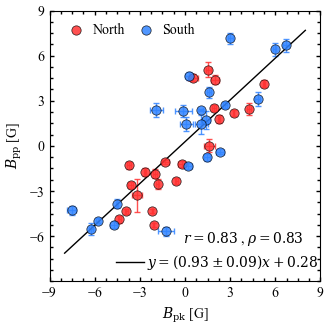

In [185]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib as mpl
import pandas as pd

mpl.style.use('/home/iron-man/Documents/long_term_reconstruction/Pix2Pix_Codes/bkj_style.mplstyle')

# ============================================================
# Data preparation
# ============================================================

df_test_N1_KP = Kitt_peak_df[['Date', 'KP_n_test_pf','KP_n_test_se']]
df_test_N2_P = Pred_df[['Date', 'n_test_pf','n_test_se']]
df_test_N1_KP = df_test_N1_KP[(df_test_N1_KP['Date'] >= 1915) & (df_test_N1_KP['Date'] <= 2003)]
df_test_N2_P = df_test_N2_P[(df_test_N2_P['Date'] >= 1915) & (df_test_N2_P['Date'] <= 2003)]

merged_n_test_P = pd.merge(df_test_N1_KP, df_test_N2_P, on='Date', how='inner')
merged_n_test_P = merged_n_test_P.dropna()


df_test_S1_KP = Kitt_peak_df[['Date', 'KP_s_test_pf','KP_s_test_se']]
df_test_S2_P = Pred_df[['Date', 's_test_pf','s_test_se']]
df_test_S1_KP = df_test_S1_KP[(df_test_S1_KP['Date'] >= 1915) & (df_test_S1_KP['Date'] <= 2003)]
df_test_S2_P = df_test_S2_P[(df_test_S2_P['Date'] >= 1915) & (df_test_S2_P['Date'] <= 2003)]

merged_s_test_P = pd.merge(df_test_S1_KP, df_test_S2_P, on='Date', how='inner')
merged_s_test_P = merged_s_test_P.dropna()

x_test = np.concatenate([
    merged_n_test_P['KP_n_test_pf'].values,
    merged_s_test_P['KP_s_test_pf'].values
])

y_test = np.concatenate([
    merged_n_test_P['n_test_pf'].values,
    merged_s_test_P['s_test_pf'].values
])


# ============================================================
# Figure
# ============================================================

fig, ax = plt.subplots(figsize=(3.5, 3.5))

# North test
test_north = ax.scatter(
    merged_n_test_P['KP_n_test_pf'].values,
    merged_n_test_P['n_test_pf'].values,
    color='#FF3333',
    edgecolor='black',
    linewidth=0.5,
    label='North',
    s=45,
    alpha=0.85,
    zorder=3
)

# South test
test_south = ax.scatter(
    merged_s_test_P['KP_s_test_pf'].values,
    merged_s_test_P['s_test_pf'].values,
    color='#3385FF',
    edgecolor='black',
    linewidth=0.5,
    label='South',
    s=45,
    alpha=0.85,
    zorder=3
)


# ============================================================
# Error bars
# ============================================================

# North
ax.errorbar(
    merged_n_test_P['KP_n_test_pf'],
    merged_n_test_P['n_test_pf'],
    xerr=merged_n_test_P['KP_n_test_se'],
    yerr=merged_n_test_P['n_test_se'],
    fmt='none',
    ecolor='#FF3333',
    elinewidth=1,
    capsize=2,
    alpha=0.85,
    zorder=2
)

# South
ax.errorbar(
    merged_s_test_P['KP_s_test_pf'],
    merged_s_test_P['s_test_pf'],
    xerr=merged_s_test_P['KP_s_test_se'],
    yerr=merged_s_test_P['s_test_se'],
    fmt='none',
    ecolor='#3385FF',
    elinewidth=1,
    capsize=2,
    alpha=0.85,
    zorder=2
)

# ============================================================
# Correlation coefficients
# ============================================================

pearson_r_test, pearson_p_test = pearsonr(x_test, y_test)
spearman_r_test, spearman_p_test = spearmanr(x_test, y_test)

coeffs, cov = np.polyfit(x_test, y_test, 1, cov=True)
slope_err_KP = np.sqrt(cov[0, 0])
slope_KP_pred_test_dataset = coeffs[0]
intercept_KP_pred_test_dataset = coeffs[1]

x_line_test = np.linspace(-8, 8, 200)
print(f"pearson_p_test:{pearson_p_test}, spearman_p_test:{spearman_p_test}")
# FIX: previously used the undefined/leftover `x_line` instead of
# x_line_test defined directly above -- now uses the correct array.
y_line_test = (
    slope_KP_pred_test_dataset * x_line_test
    + intercept_KP_pred_test_dataset
)

# fit_test, = ax.plot(
#     x_line_test, y_line_test,
#     color='black',
#     lw=1.2,
#     # linestyle='--',
#     zorder=2,
#     label='Best fit line'
# )

fit_test, = ax.plot(
    x_line_test, y_line_test,
    color='black',
    lw=1.0,
    zorder=2,
    label=fr'$y=({slope_KP_pred_test_dataset:.2f}\pm{slope_err_KP:.2f})x+{intercept_KP_pred_test_dataset:.2f}$'
)
# ============================================================
# Stats annotation (top-left, away from data/legend, with a
# background box so it never blends into the points behind it)
# ============================================================

stats_text_test = (
    fr'$r = {pearson_r_test:.2f}$ , '
    fr'$\rho = {spearman_r_test:.2f}$'
    # '\n'
    # fr'$y=({slope_KP_pred_test_dataset:.2f}\pm{slope_err_KP:.2f})x+{intercept_KP_pred_test_dataset:.2f}$'
)

ax.text(
    0.492, 0.19,
    stats_text_test,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    horizontalalignment='left',
)



ax.set_xlabel(r"$B_{\mathrm{pk}}$ [G]")
ax.set_ylabel(r"$B_{\mathrm{pp}}$ [G]")
# ax.grid(True, linestyle='--', alpha=0.35, zorder=0)
ax.grid(False)
ax.set_xlim(-9, 9)
ax.set_ylim(-9, 9)
ax.set_xticks(np.arange(-9, 10, 3))
ax.set_yticks(np.arange(-6, 10, 3))
ax.set_aspect('equal', adjustable='box')
ax.tick_params(axis='both')
# ============================================================
# Legend -- placed outside a data-dense region (bottom-right,
# below the fit line's lower tail) with its own background box
# so it no longer overlaps the stats text or scattered points.
# ============================================================

# legend = ax.legend(
#     handles=[test_north, test_south],
#     loc='upper left',
#     # frameon=True,
#     fontsize=14,
#     handletextpad=0.5,
#     borderpad=0.5,
#     labelspacing=0.5,
# )

# First row: North and South
legend1 = ax.legend(
    handles=[test_north, test_south],
    loc='upper left',
    # bbox_to_anchor=(0.54, 0.24),
    fontsize=10,
    ncol=2,
    columnspacing=0.5,  # Reduce gap between North and South
    handletextpad=0.2,
    borderpad=0.4,
    labelspacing=0.2,
)

ax.add_artist(legend1)

# Second row: Best-fit line
legend2 = ax.legend(
    handles=[fit_test],
    loc='upper left',
    bbox_to_anchor=(0.2, 0.15),
    fontsize=10,
    ncol=1,
    handletextpad=0.2,
    borderpad=0.4,
    labelspacing=0.5,
)
plt.tight_layout()

plt.savefig(
    'Polar_field_scatter_test.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'Polar_field_scatter_test.png',
    format='png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
from scipy.stats import pearsonr, spearmanr
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
dfN1_KP = Kitt_peak_df[['Date','KP_N_pf']]
dfN2_P = Pred_df[['Date','pred_N_pf']]


dfN1_KP = dfN1_KP[(dfN1_KP['Date'] >= 1915) & (dfN1_KP['Date'] <= 2003)]
dfN2_P = dfN2_P[(dfN2_P['Date'] >= 1915) & (dfN2_P['Date'] <= 2003)]
merged_N_P = pd.merge(dfN1_KP, dfN2_P, on='Date', how='inner')
merged_N_P = merged_N_P.dropna()


dfS1_KP = Kitt_peak_df[['Date','KP_S_pf']]
dfS2_P = Pred_df[['Date','pred_S_pf']]


dfS1_KP = dfS1_KP[(dfS1_KP['Date'] >= 1915) & (dfS1_KP['Date'] <= 2003)]
dfS2_P = dfS2_P[(dfS2_P['Date'] >= 1915) & (dfS2_P['Date'] <= 2003)]
merged_S_P = pd.merge(dfS1_KP, dfS2_P, on='Date', how='inner')
merged_S_P = merged_S_P.dropna()
x = np.concatenate([
    merged_N_P['KP_N_pf'].values,
    merged_S_P['KP_S_pf'].values
])

y = np.concatenate([
    merged_N_P['pred_N_pf'].values,
    merged_S_P['pred_S_pf'].values
])
# Correlation coefficients
pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

# slope_pred, intercept_pred = np.polyfit(x, y, 1)
coeffs, cov = np.polyfit(x, y, 1, cov=True)

slope_KP_pred = coeffs[0]
intercept_KP_pred = coeffs[1]

slope_KP_err = np.sqrt(cov[0,0])
y_KP_pred = (y-intercept_KP_pred)/slope_KP_pred
# Calculate metrics
n_KP_pred = len(x)
mse_KP_pred = np.mean((y_KP_pred - x) ** 2) # Mean Squared Error
rmse_KP_pred = np.sqrt(mse_KP_pred)              # Root Mean Squared Error
mae_KP_pred = np.mean(np.abs(y_KP_pred - x)) # Mean Absolute Error
# r2_pred = r2_score(x, y_pred)         # R-squared
r2_calibration = r2_score(x, y_KP_pred)  
# Print results
print("=" * 50)
print("PREDICTED vs Kitt Peak")
print("=" * 50)
print("Slope_pred:", slope_KP_pred)
print("slope error:" , slope_KP_err)
print("Intercept_pred:", intercept_KP_pred)
print(f"RMSE:      {rmse_KP_pred:.4f}")
print(f"MAE:       {mae_KP_pred:.4f}")
print(f"R²_cal:        {r2_calibration:.4f}")
print(f"Pearson r:     {pearson_r:.4f}  (p={pearson_p:.2e})")
print(f"Spearman rho:  {spearman_r:.4f}  (p={spearman_p:.2e})")
print(f"n (points): {n_KP_pred}")




/tmp/ipykernel_58055/3967307820.py:285: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


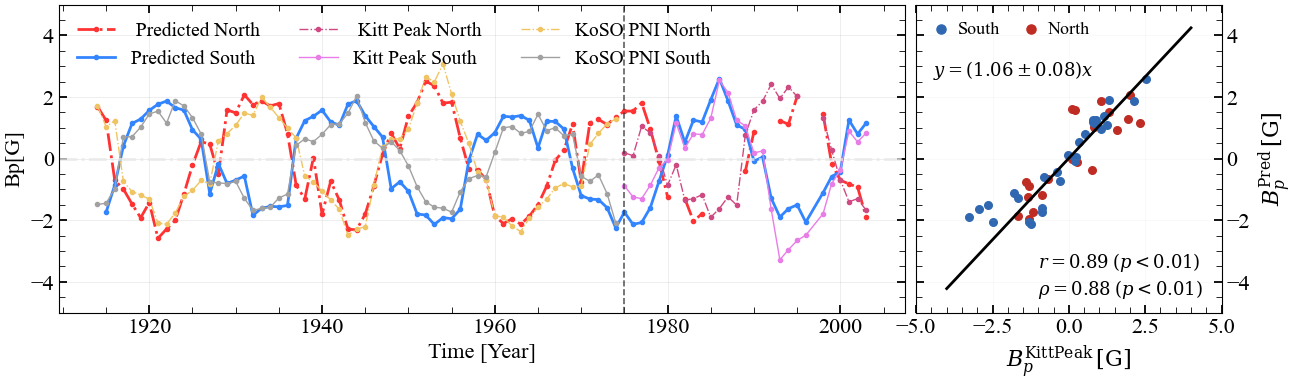

In [20]:
from matplotlib.gridspec import GridSpec
# Check available fonts and set publication-ready style
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
polar_df = polar_df[
    (polar_df['Date'] >= 1914) &
    (polar_df['Date'] < 1975)
].reset_index(drop=True)
polar_df.head()
import matplotlib as mpl
mpl.style.use('/home/iron-man/Documents/long_term_reconstruction/Pix2Pix_Codes/bkj_style.mplstyle')

scaling_factor_pred = slope_pred
intercept_pred = intercept_pred
scaling_factor_KP = slope_KP
intercept_KP = intercept_KP

scaling_factor_KP_pred = slope_KP_pred
intercept_KP_pred = intercept_KP_pred
fig = plt.figure(figsize=(15,4))

gs = GridSpec(
    1, 2,
    width_ratios=[3.6, 1.3],   # left much wider than right
    wspace=0.02                # almost touching
)

ax1 = fig.add_subplot(gs[0])   # time series
ax2 = fig.add_subplot(gs[1])   # scatter






# color=[orange,#17BECF],hotpink,crimson,#7B3F00,#90EE90

# --------------------------
# Pred (Model)
# --------------------------
ax1.plot(
    Pred_df['Date'], 
    (Pred_df['pred_N_pf']-intercept_pred)/scaling_factor_pred,
    color="#FF3333",
    linestyle="-.",
    marker="o",
    markersize=3,
    linewidth=2.0,
    label=" Predicted North"
)

ax1.plot(
    Pred_df['Date'], 
    (Pred_df['pred_S_pf']-intercept_pred)/scaling_factor_pred,
    color="#3385FF",
    marker="o",
    markersize=3,
    linewidth=2.0,
    label="Predicted South"
)


# --------------------------
# Kitt Peak (Original)
# --------------------------
ax1.plot(
    Kitt_peak_df['Date'], 
    (Kitt_peak_df['KP_N_pf']-intercept_KP)/scaling_factor_KP,
    color="#CF4A82",
    linestyle="-.",
    marker="o",
    markersize=3,
    linewidth=1,
    label=" Kitt Peak North"
)

ax1.plot(
    Kitt_peak_df['Date'], 
    (Kitt_peak_df['KP_S_pf']-intercept_KP)/scaling_factor_KP,
    color="#E87DE8",
    marker="o",
    markersize=3,
    linewidth=1,
    label="Kitt Peak South"
)



# --------------------------
# PNI (KoSO)
# --------------------------
ax1.plot(
    polar_df["Date"],
    polar_df["North PNI"],
    color="#F0C462",
    linestyle="-.",
    marker="o",
    markersize=3,
    linewidth=1,
    label="KoSO PNI North"
)

ax1.plot(
    polar_df["Date"],
    polar_df["South PNI"],
    color="#A1A1A1",
    marker="o",
    markersize=3,
    linewidth=1,
    label="KoSO PNI South"
)

# Zero line
ax1.axhline(
    0,
    color="#E8E8E8",
    linestyle="-.",
    linewidth=2,
    alpha=0.8
)
date_1975 = Kitt_peak_df.loc[
    Kitt_peak_df['Date'] == 1975,
    'Date'
].iloc[0]

ax1.axvline(
    x=date_1975,
    color="#363636",
    linestyle="--",
    linewidth=1.2,
    alpha=0.8
)
# Labels
ax1.set_xlabel("Time [Year]", fontsize=16)
ax1.set_ylabel("Bp[G]", fontsize=16)
# Y-axis limits
ax1.set_ylim(-5, 5)


ax1.tick_params(
    axis='both',
    which='major',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    length=6,
    width=1.3,
    labelsize=16   # Increase tick label font size
)

ax1.tick_params(
    axis='both',
    which='minor',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    length=4,
    width=0.6,
)

# ax1.set_xlim(
#     pd.Timestamp("1910-01-01"),
#     pd.Timestamp("2005-12-31")
# )
# Legend
ax1.legend(
    ncol=3,
    loc="upper left",
    frameon=False,
    fontsize=14
)
ax1.grid(alpha=0.3)



# Regression line
# x_line = np.linspace(min(x), max(x), 200)
x_line = np.linspace(-4, 4, 200)
y_line = slope_KP_pred * x_line + intercept_KP_pred
# y_line = x_line


# Scatter plots
North = ax2.scatter(
    (merged_N_P['KP_N_pf']- intercept_KP) / scaling_factor_KP,
    # merged_N_P['North_pf'],
    (merged_N_P['pred_N_pf']- intercept_KP_pred) / scaling_factor_pred,
    color=(191/255,44/255,35/255),
    label='North',
    s=30
)

South = ax2.scatter(
    (merged_S_P['KP_S_pf']- intercept_KP) / scaling_factor_KP,
    # merged_S_P['South_pf'],
    (merged_S_P['pred_S_pf']- intercept_pred) / scaling_factor_pred,
    color=(47/255,103/255,177/255),
    label='South',
    s=30
)


fit, = ax2.plot(
    x_line, y_line,
    color='black',
    lw=2,
    label=fr'$y=({slope_KP_pred:.2f}\pm{slope_KP_err:.2f})x$'
)
# --- Text annotation with stats ---
# stats_text = (
#     f"r = {pearson_r:.2f}  "
#     f" ρ = {spearman_r:.2f}\n"
#     # f"n = {n_pred}"
# )
stats_text = (
    fr"$r = {pearson_r:.2f}$ $(p<0.01)$" "\n"
    fr"$\rho = {spearman_r:.2f}$ $(p<0.01)$"
)

fit_text = fr"$y = ({slope_KP_pred:.2f}\pm{slope_KP_err:.2f})x$"
ax2.text(
    0.40,0.20, stats_text,
    transform=plt.gca().transAxes,
    fontsize=13,
    verticalalignment='top',
    horizontalalignment='left'
)
ax2.text(
    0.58,0.75, fit_text,
    transform=plt.gca().transAxes,
    fontsize=13,
    verticalalignment='bottom',
    horizontalalignment='right'
)

# ----- Y-AXIS ON RIGHT SIDE -----
ax2.yaxis.set_label_position("right")
ax2.yaxis.tick_right()
ax2.set_ylim(-5, 5)
ax2.set_xlim(-5, 5)
ax2.tick_params(
    axis='both',
    which='minor',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    length=4,
    width=0.6,
)
ax2.tick_params(
    axis='both',
    which='major',
    direction='in',
    top=True,
    bottom=True,
    left=True,
    right=True,
    length=6,
    width=1.3,
    labelsize=16
)

ax2.set_xlabel(r"$B_p^{\mathrm{KittPeak}}\,[\mathrm{G}]$", fontsize=16)
ax2.set_ylabel(r"$B_p^{\mathrm{Pred}}\,[\mathrm{G}]$", fontsize=16)
ax2.grid(True)
ax2.legend(
    handles=[South,North],
    loc='upper left',
    ncol=2,
    fontsize=13,
    handletextpad=0.4,   # space between marker and text
    columnspacing=1.2,   # space between columns
    handlelength=1.0,    # length of legend handle
    markerscale=1.2
)

fig.tight_layout()

fig.savefig(
    "Polar_field_prediction.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

# Optional PNG version
fig.savefig(
    "Polar_field_prediction.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()